In [1]:
import os
import pandas as pd


def doc_csv(ten_tep):
    """Doc tep csv trong thu muc data/, neu khong co thi doc o thu muc hien tai."""
    duong_dan = os.path.join("data", ten_tep)
    if not os.path.exists(duong_dan):
        duong_dan = ten_tep
    return pd.read_csv(duong_dan)

## 2. Đường có lề rộng nhất

In [2]:
# -*- coding: utf-8 -*-
"""Bước 1: tìm đường có lề rộng nhất và các vectơ hỗ trợ.

Chú thích viết tiếng Việt có dấu, phần in ra màn hình viết không dấu.
"""

import numpy as np
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

# 24 điểm, hai cụm tách hẳn nhau
X, y = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]],
                    cluster_std=0.9, random_state=0)
y = 1 - y            # lớp 1 là cụm dưới bên trái, giống hình trên slide

# C rất lớn nghĩa là không cho điểm nào nằm trong lề
svm = SVC(kernel="linear", C=1000)
svm.fit(X, y)

w = svm.coef_[0]
b = svm.intercept_[0]
print(f"w1 = {w[0]:.3f}, w2 = {w[1]:.3f}, b = {b:.3f}")
do_dai_w = np.sqrt(w[0] ** 2 + w[1] ** 2)
print(f"Do rong cua le = 2 / {do_dai_w:.4f} = {2 / do_dai_w:.4f}")
print()

# Các vectơ hỗ trợ nằm đúng trên hai mép lề, nơi f(x) bằng 1 hoặc -1
print("So vecto ho tro:", len(svm.support_))
for i in svm.support_:
    f = svm.decision_function(X[i:i + 1])[0]
    print(f" diem {i:2d}: x1 = {X[i, 0]:.2f}, x2 = {X[i, 1]:.2f},"
        f" lop {y[i]}, f(x) = {f:+.3f}")
print()

# Những điểm khác nằm ngoài lề, nên |f(x)| lớn hơn 1
f_tat_ca = svm.decision_function(X)
ngoai = np.setdiff1d(np.arange(len(X)), svm.support_)
nho_nhat = np.abs(f_tat_ca[ngoai]).min()
print(f"|f(x)| nho nhat cua cac diem khac: {nho_nhat:.3f}")
print()

# Học lại chỉ với các vectơ hỗ trợ
chi_sv = SVC(kernel="linear", C=1000)
chi_sv.fit(X[svm.support_], y[svm.support_])
w2 = chi_sv.coef_[0]
print("Hoc lai chi voi vecto ho tro:")
b2 = chi_sv.intercept_[0]
print(f" w1 = {w2[0]:.3f}, w2 = {w2[1]:.3f}, b = {b2:.3f}")
print()

# Dự đoán cho hai điểm mới
moi = np.array([[3.0, 3.0], [5.0, 4.5]])
for diem, f, lop in zip(moi, svm.decision_function(moi),
                        svm.predict(moi)):
    print(f"Diem ({diem[0]}, {diem[1]}): f(x) = {f:+.3f}, doan lop {lop}")

w1 = -0.831, w2 = -0.355, b = 4.820
Do rong cua le = 2 / 0.9039 = 2.2126

So vecto ho tro: 3
 diem 18: x1 = 5.20, x2 = 4.22, lop 0, f(x) = -1.000
 diem 10: x1 = 2.88, x2 = 4.02, lop 1, f(x) = +1.000
 diem 13: x1 = 3.59, x2 = 2.36, lop 1, f(x) = +1.000

|f(x)| nho nhat cua cac diem khac: 1.059

Hoc lai chi voi vecto ho tro:
 w1 = -0.831, w2 = -0.355, b = 4.821

Diem (3.0, 3.0): f(x) = +1.262, doan lop 1
Diem (5.0, 4.5): f(x) = -0.933, doan lop 0


## 3. Lề mềm và tham số C

In [3]:
# -*- coding: utf-8 -*-
"""Bước 2: lề mềm, tham số C, và vì sao SVM phải chuẩn hoá."""

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

df = doc_csv("sinh_vien.csv")
X = df[["gio_on", "diem_giua_ky"]]
y = df["qua_mon"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("Tap hoc co", len(X_tr), "ban")
print("    C    so vecto HT   do rong le    tap hoc   tap kiem tra")
for C in [0.01, 0.1, 1, 10, 100]:
    mh = make_pipeline(StandardScaler(),
                        SVC(kernel="linear", C=C))
    mh.fit(X_tr, y_tr)
    svm = mh[-1]                    # bước cuối của pipeline là SVM
    le = 2 / np.linalg.norm(svm.coef_[0])
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    print(f" {C:6}    {len(svm.support_):6d}        {le:6.2f}"
        f"      {a_hoc:.4f}     {a_kt:.4f}")
print()

# Bộ sinh viên mở rộng có thêm cột chi tiêu, tính bằng nghìn đồng
df3 = doc_csv("sinh_vien_mo_rong.csv")
X3 = df3[["gio_on", "diem_giua_ky", "chi_tieu"]]
y3 = df3["qua_mon"]
X3_tr, X3_te, y3_tr, y3_te = train_test_split(
    X3, y3, test_size=0.25, random_state=17, stratify=y3
)
tho = SVC().fit(X3_tr, y3_tr)
chuan = make_pipeline(StandardScaler(), SVC()).fit(X3_tr, y3_tr)
print("Ba cot, kernel RBF mac dinh")
print(f" Doan bua ca lop qua : {y3_te.mean():.4f}")
print(f" Khong chuan hoa      : "
        f"{accuracy_score(y3_te, tho.predict(X3_te)):.4f}")
print(f" Co chuan hoa         : "
        f"{accuracy_score(y3_te, chuan.predict(X3_te)):.4f}")

Tap hoc co 90 ban
    C    so vecto HT   do rong le    tap hoc   tap kiem tra
   0.01        74          3.84      0.8556     0.8667
    0.1        44          1.70      0.8889     0.9000
      1        31          1.29      0.8778     0.9000
     10        28          1.06      0.9000     0.9000
    100        27          1.05      0.9000     0.9000

Ba cot, kernel RBF mac dinh
 Doan bua ca lop qua : 0.6000
 Khong chuan hoa      : 0.6000
 Co chuan hoa         : 0.9000


## 4. Kernel và biên cong

In [4]:
# -*- coding: utf-8 -*-
"""Bước 3: nâng chiều bằng tay, rồi để kernel làm việc đó."""

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Phần 1: dữ liệu một chiều, lớp 1 nằm giữa, lớp 0 ở hai đầu
x = np.array([-4.0, -3.4, -2.8, -2.2, -1.2, -0.7, -0.2,
                0.3, 0.8, 1.3, 2.3, 2.9, 3.5, 4.0])
y = (np.abs(x) < 1.8).astype(int)

# Thử mọi ngưỡng: đoán lớp 1 khi x nhỏ hơn hoặc bằng ngưỡng
tot = max(((x <= t).astype(int) == y).mean() for t in x)
print(f"Mot nguong tren truc x, tot nhat dung {tot:.4f}")

# Thêm cột x binh phuong rồi dùng SVM tuyến tính
X_moi = np.c_[x, x ** 2]
svm = SVC(kernel="linear", C=1000).fit(X_moi, y)
print(f"Them cot x^2, SVM tuyen tinh dung {svm.score(X_moi, y):.4f}")
print()

# Phần 2: hai vầng trăng, để kernel tự nâng chiều
df = doc_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

mo_hinh = {
    "SVM kernel tuyen tinh": SVC(kernel="linear"),
    "SVM kernel da thuc bac 3": SVC(kernel="poly", degree=3),
    "SVM kernel RBF": SVC(kernel="rbf"),
    "Hoi quy logistic": LogisticRegression(),
    "KNN, k = 13": KNeighborsClassifier(n_neighbors=13),
}
print("Hai vang trang, accuracy tren tap kiem tra")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    acc = accuracy_score(y_te, mh.predict(X_te))
    print(f" {ten:26s} {acc:.4f}")
print()

rbf = mo_hinh["SVM kernel RBF"]
print("So vecto ho tro cua kernel RBF:", len(rbf.support_),
        "tren", len(X_tr), "diem hoc")

Mot nguong tren truc x, tot nhat dung 0.7143
Them cot x^2, SVM tuyen tinh dung 1.0000

Hai vang trang, accuracy tren tap kiem tra
 SVM kernel tuyen tinh      0.8667
 SVM kernel da thuc bac 3   0.8667
 SVM kernel RBF             0.9200
 Hoi quy logistic           0.8533
 KNN, k = 13                0.9200

So vecto ho tro cua kernel RBF: 89 tren 225 diem hoc


## 5. Chọn C và gamma

In [5]:
# -*- coding: utf-8 -*-
"""Bước 4: ảnh hưởng của gamma, rồi dò lưới C và gamma."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.svm import SVC

df = doc_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("gamma   tap hoc   tap kiem tra   so vecto HT")
for g in [0.1, 1, 10, 100]:
    mh = SVC(kernel="rbf", gamma=g).fit(X_tr, y_tr)
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    print(f" {g:5} {a_hoc:.4f}      {a_kt:.4f}          "
        f"{len(mh.support_)}")
print()

# Dò lưới: thử mọi cặp bằng kiểm định chéo 5 phần, chỉ trên tập học
luoi = {"C": [0.1, 1, 10, 100], "gamma": [0.01, 0.1, 1, 10]}
tim = GridSearchCV(SVC(kernel="rbf"), luoi, cv=5)
tim.fit(X_tr, y_tr)

bang = pd.DataFrame(tim.cv_results_["params"])
bang["diem"] = tim.cv_results_["mean_test_score"]
print("Diem kiem dinh cheo, hang la C, cot la gamma")
print(bang.pivot(index="C", columns="gamma",
                values="diem").round(4).to_string())
print()

print("Cap tot nhat:", tim.best_params_)
print(f"Diem kiem dinh cheo: {tim.best_score_:.4f}")
# GridSearchCV đã tự học lại với cặp tốt nhất trên toàn tập học
print(f"Accuracy tren tap kiem tra: {tim.score(X_te, y_te):.4f}")

gamma   tap hoc   tap kiem tra   so vecto HT
   0.1 0.8356      0.8533          113
     1 0.8711      0.9200          88
    10 0.8978      0.9067          128
   100 0.9422      0.8133          217



Diem kiem dinh cheo, hang la C, cot la gamma
gamma   0.01    0.10    1.00    10.00
C                                    
0.1    0.6578  0.8044  0.8444  0.8578
1.0    0.8044  0.8178  0.8667  0.8667
10.0   0.8178  0.8400  0.8711  0.8311
100.0  0.8178  0.8533  0.8711  0.7467

Cap tot nhat: {'C': 10, 'gamma': 1}
Diem kiem dinh cheo: 0.8711
Accuracy tren tap kiem tra: 0.9200


## 6. Nhận dạng chữ số viết tay

In [6]:
# -*- coding: utf-8 -*-
"""Bước 5: nhận dạng chữ số viết tay bằng SVM."""

import numpy as np
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
print("Kich thuoc X:", X.shape)
print("Do sang nho nhat va lon nhat:", X.min(), X.max())
print("So anh moi chu so:", np.bincount(y))
print()

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

svm = SVC(kernel="rbf").fit(X_tr, y_tr)
du_doan = svm.predict(X_te)
print(f"SVM kernel RBF: accuracy {accuracy_score(y_te, du_doan):.4f}")
print("So vecto ho tro:", len(svm.support_), "tren", len(X_tr), "anh")
sai = np.flatnonzero(du_doan != y_te)
print("So anh doan sai:", len(sai), "tren", len(y_te))
for i in sai:
    print(f" anh {i:3d}: that la {y_te[i]}, doan la {du_doan[i]}")
print()

# So với các mô hình đã học
mo_hinh = {
    "SVM co chuan hoa": make_pipeline(StandardScaler(), SVC()),
    "KNN, k = 5": KNeighborsClassifier(),
    "Logistic co chuan hoa": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000)),
}
print("Cac mo hinh khac, accuracy tren tap kiem tra")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    acc = accuracy_score(y_te, mh.predict(X_te))
    print(f" {ten:22s} {acc:.4f}")

Kich thuoc X: (1797, 64)
Do sang nho nhat va lon nhat: 0.0 16.0
So anh moi chu so: [178 182 177 183 181 182 181 179 174 180]

SVM kernel RBF: accuracy 0.9911
So vecto ho tro: 626 tren 1347 anh
So anh doan sai: 4 tren 450
 anh   6: that la 9, doan la 3
 anh  18: that la 8, doan la 1
 anh 161: that la 4, doan la 8
 anh 428: that la 7, doan la 9

Cac mo hinh khac, accuracy tren tap kiem tra
 SVM co chuan hoa       0.9778
 KNN, k = 5             0.9867
 Logistic co chuan hoa  0.9711


# 7. Bài tập

In [7]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits, make_blobs, make_classification
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC


def doc_csv(ten_tep):
    """Doc tep csv trong thu muc data/, neu khong co thi doc o thu muc hien tai."""
    duong_dan = os.path.join("data", ten_tep)
    if not os.path.exists(duong_dan):
        duong_dan = ten_tep
    return pd.read_csv(duong_dan)


# 24 diem cua muc 2, hai cum tach han nhau (lop 1 la cum duoi ben trai)
X_diem, y_diem = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]],
                            cluster_std=0.9, random_state=0)
y_diem = 1 - y_diem

svm = SVC(kernel="linear", C=1000).fit(X_diem, y_diem)
w = svm.coef_[0]
b = svm.intercept_[0]
print(f"w1 = {w[0]:.3f}, w2 = {w[1]:.3f}, b = {b:.3f}, "
      f"so vecto ho tro = {len(svm.support_)}")

# Bo hai vang trang cua muc 5, chia 75/25 giong het tai lieu
df = doc_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Cap tot nhat cua muc 5 de lam moc so sanh cho bai 3 va bai 4
tim_rbf = GridSearchCV(SVC(kernel="rbf"),
                       {"C": [0.1, 1, 10, 100], "gamma": [0.01, 0.1, 1, 10]},
                       cv=5).fit(X_tr, y_tr)
print("RBF muc 5:", tim_rbf.best_params_,
      f"| diem kiem dinh cheo {tim_rbf.best_score_:.4f}",
      f"| tap kiem tra {tim_rbf.score(X_te, y_te):.4f}")

w1 = -0.831, w2 = -0.355, b = 4.820, so vecto ho tro = 3


RBF muc 5: {'C': 10, 'gamma': 1} | diem kiem dinh cheo 0.8711 | tap kiem tra 0.9200


## Bài tập 1: Tính tay khoảng cách tới ranh giới

In [8]:
# Tu tinh f(x) bang phep nhan va cong, khong dung decision_function
def tinh_f(diem):
    return w[0] * diem[0] + w[1] * diem[1] + b


do_dai_w = np.sqrt(w[0] ** 2 + w[1] ** 2)
print(f"Do dai w = {do_dai_w:.4f}, do rong le = 2 / {do_dai_w:.4f} = {2 / do_dai_w:.4f}")
print(f"Mot nua do rong le = {1 / do_dai_w:.4f}")
print()

print("Diem moi")
for diem in [(3.0, 3.0), (5.0, 4.5)]:
    f = tinh_f(diem)
    khoang_cach = abs(f) / do_dai_w
    print(f" ({diem[0]}, {diem[1]}): f(x) = {f:+.3f}, khoang cach toi ranh gioi = {khoang_cach:.4f}")
print()

print("Ba vecto ho tro")
for i in svm.support_:
    f = tinh_f(X_diem[i])
    khoang_cach = abs(f) / do_dai_w
    print(f" diem {i:2d}: f(x) = {f:+.3f}, khoang cach = {khoang_cach:.4f}")

# Doi chieu voi thu vien sau khi da tu tinh xong
f_thu_vien = svm.decision_function(np.array([[3.0, 3.0], [5.0, 4.5]]))
print()
print("Doi chieu voi decision_function:", np.round(f_thu_vien, 3))

Do dai w = 0.9039, do rong le = 2 / 0.9039 = 2.2126
Mot nua do rong le = 1.1063

Diem moi
 (3.0, 3.0): f(x) = +1.262, khoang cach toi ranh gioi = 1.3958
 (5.0, 4.5): f(x) = -0.933, khoang cach toi ranh gioi = 1.0325

Ba vecto ho tro
 diem 18: f(x) = -1.000, khoang cach = 1.1064
 diem 10: f(x) = +1.000, khoang cach = 1.1062
 diem 13: f(x) = +1.000, khoang cach = 1.1065

Doi chieu voi decision_function: [ 1.262 -0.933]


**Nhận xét:** Tự tính bằng phép nhân và cộng, f(3, 3) = −0.831·3 − 0.355·3 + 4.820 = +1.262 và f(5, 4.5) = −0.933, trùng với `decision_function`. Chia |f(x)| cho độ dài của w (0.9039) ra khoảng cách tới ranh giới: điểm (3, 3) cách 1.3958, điểm (5, 4.5) cách 1.0325. Ba vectơ hỗ trợ cách ranh giới 1.1064, 1.1062 và 1.1065, tức là bằng nhau và bằng một nửa độ rộng lề (2.2126 / 2 = 1.1063), chênh ở chữ số thập phân thứ tư là sai số tính gần đúng của thư viện.

## Bài tập 2: Thêm một điểm

Ban dau: w1 = -0.831, w2 = -0.355, b = 4.820

Lan 1: them diem lop 1 tai (-1, -1)
  w1 = -0.831, w2 = -0.355, b = 4.820, le = 2.2126, so vecto ho tro = 3
  vecto ho tro co phai la diem moi khong: False

Lan 2: them diem lop 1 tai (4.5, 4)
  w1 = -2.603, w2 = -0.807, b = 15.941, le = 0.7339, so vecto ho tro = 2
  vecto ho tro co phai la diem moi khong: True

f(4.5, 4) theo duong ban dau = -0.340 -> SAI phia (phia lop 0)
Lan 2 co con tach hoan toan duoc khong: True


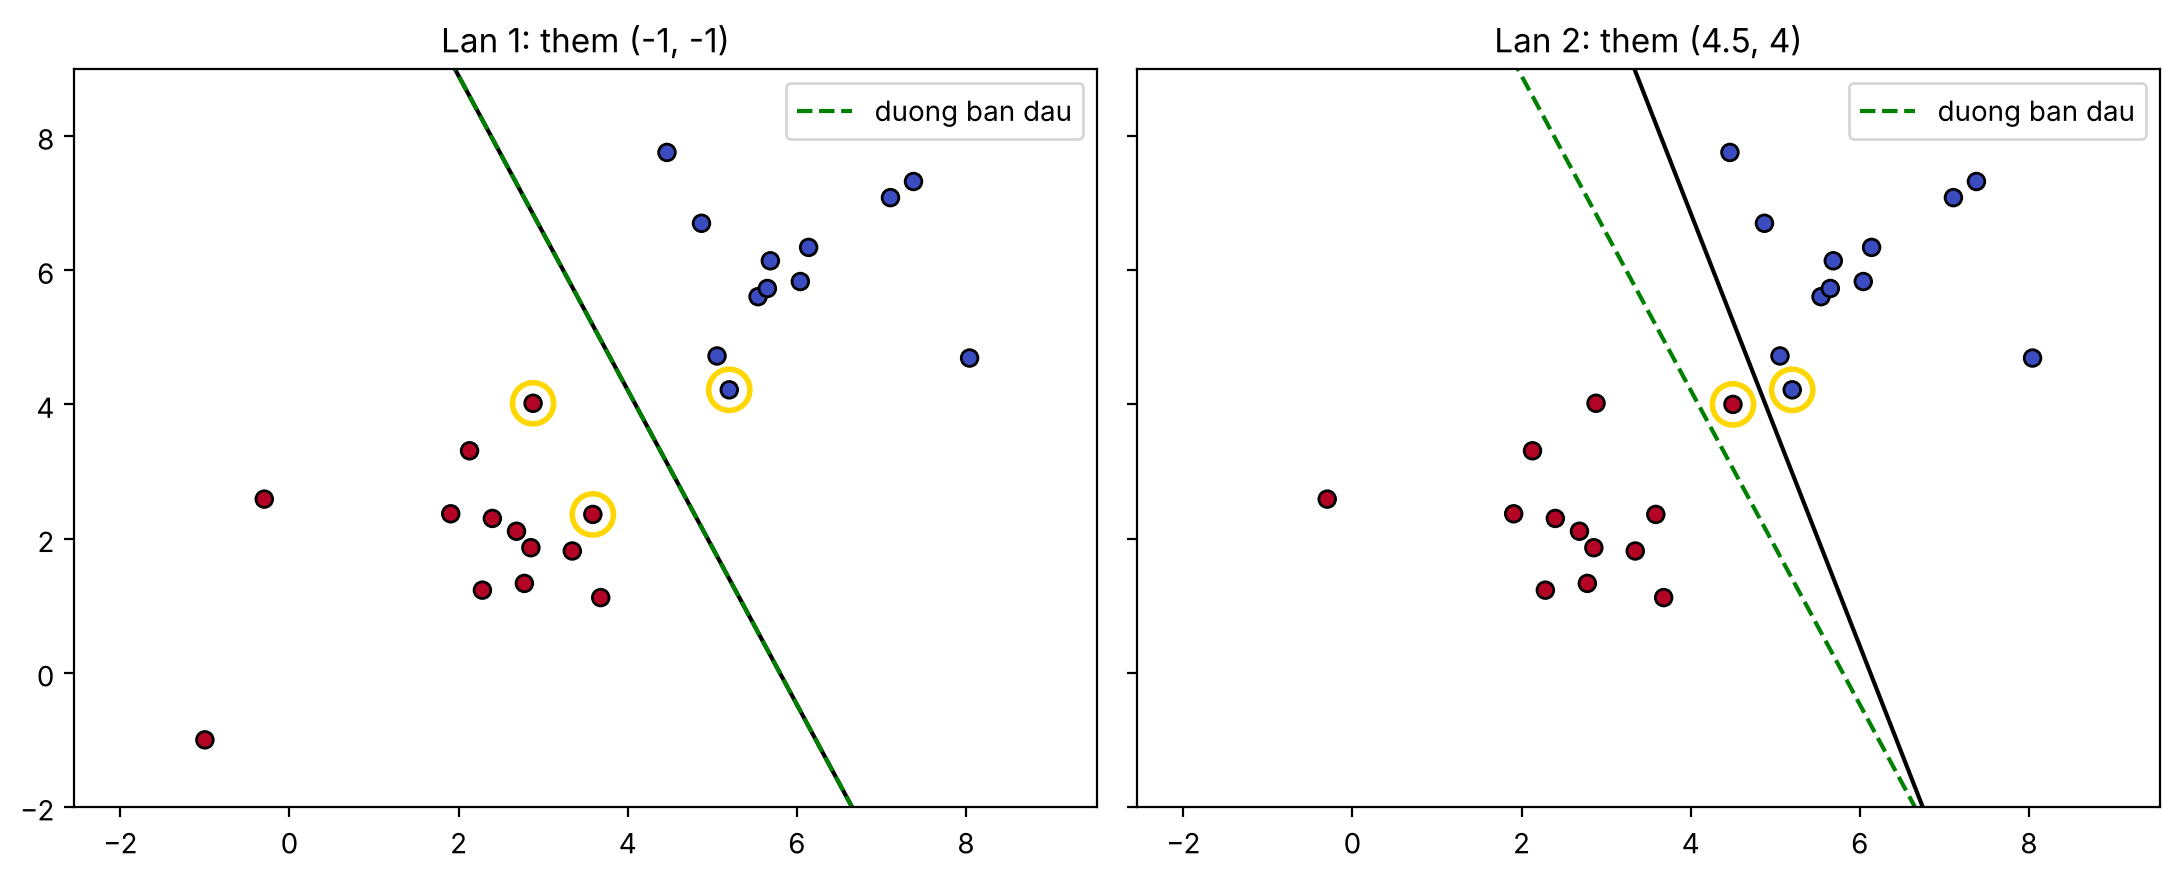

In [9]:
def hoc_va_in(ten, X_moi, y_moi):
    mo_hinh = SVC(kernel="linear", C=1000).fit(X_moi, y_moi)
    w_moi = mo_hinh.coef_[0]
    b_moi = mo_hinh.intercept_[0]
    do_dai = np.sqrt((w_moi ** 2).sum())
    print(f"{ten}")
    print(f"  w1 = {w_moi[0]:.3f}, w2 = {w_moi[1]:.3f}, b = {b_moi:.3f}, "
          f"le = {2 / do_dai:.4f}, so vecto ho tro = {len(mo_hinh.support_)}")
    print(f"  vecto ho tro co phai la diem moi khong:", (len(X_moi) - 1) in mo_hinh.support_)
    return mo_hinh


print("Ban dau: w1 = %.3f, w2 = %.3f, b = %.3f" % (w[0], w[1], b))
print()

# Lan 1: them diem lop 1 tai (-1, -1), nam sau trong vung lop 1
X_lan1 = np.vstack([X_diem, [-1, -1]])
y_lan1 = np.append(y_diem, 1)
mo_hinh_lan1 = hoc_va_in("Lan 1: them diem lop 1 tai (-1, -1)", X_lan1, y_lan1)
print()

# Lan 2: bo diem do, them diem lop 1 tai (4.5, 4)
X_lan2 = np.vstack([X_diem, [4.5, 4]])
y_lan2 = np.append(y_diem, 1)
mo_hinh_lan2 = hoc_va_in("Lan 2: them diem lop 1 tai (4.5, 4)", X_lan2, y_lan2)
print()

# Diem (4.5, 4) nam o phia nao cua duong ranh gioi ban dau?
f_diem_moi = w[0] * 4.5 + w[1] * 4 + b
print(f"f(4.5, 4) theo duong ban dau = {f_diem_moi:+.3f} "
      f"-> {'dung phia lop 1' if f_diem_moi > 0 else 'SAI phia (phia lop 0)'}")
print("Lan 2 co con tach hoan toan duoc khong:",
      accuracy_score(y_lan2, mo_hinh_lan2.predict(X_lan2)) == 1.0)

# Ve hai lan de nhin
fig, truc = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, (tieu_de, Xv, yv, mh) in zip(truc, [
        ("Lan 1: them (-1, -1)", X_lan1, y_lan1, mo_hinh_lan1),
        ("Lan 2: them (4.5, 4)", X_lan2, y_lan2, mo_hinh_lan2)]):
    ax.scatter(Xv[:, 0], Xv[:, 1], c=yv, cmap="coolwarm", edgecolor="k")
    ax.scatter(Xv[mh.support_, 0], Xv[mh.support_, 1], s=220,
               facecolors="none", edgecolors="gold", linewidths=2)
    xs = np.linspace(-2, 9, 50)
    w_v, b_v = mh.coef_[0], mh.intercept_[0]
    ax.plot(xs, -(w_v[0] * xs + b_v) / w_v[1], "k-")
    ax.plot(xs, -(w[0] * xs + b) / w[1], "g--", label="duong ban dau")
    ax.set_ylim(-2, 9)
    ax.set_title(tieu_de)
    ax.legend()
plt.tight_layout()
plt.show()

**Nhận xét:** Lần 1, thêm điểm lớp 1 tại (−1, −1), đường ranh giới **không đổi**: vẫn w1 = −0.831, w2 = −0.355, b = 4.820, lề 2.2126 và 3 vectơ hỗ trợ cũ. Lần 2, thêm điểm lớp 1 tại (4.5, 4), đường ranh giới **đổi hẳn**: w1 = −2.603, w2 = −0.807, b = 15.941, lề co lại từ 2.2126 còn 0.7339, và chỉ còn 2 vectơ hỗ trợ, trong đó có chính điểm mới.

## Bài tập 3: Kernel đa thức

In [10]:
print("bac   C tot nhat   diem kiem dinh cheo   tap kiem tra")
ket_qua_poly = {}
for bac in [2, 3, 4]:
    luoi = {"svc__C": [0.1, 1, 10, 100]}
    mo_hinh = make_pipeline(StandardScaler(), SVC(kernel="poly", degree=bac))
    tim = GridSearchCV(mo_hinh, luoi, cv=5).fit(X_tr, y_tr)
    ket_qua_poly[bac] = (tim.best_params_["svc__C"], tim.best_score_,
                         tim.score(X_te, y_te))
    c_tot, diem_cv, acc_kt = ket_qua_poly[bac]
    print(f" {bac}    {c_tot:>8}        {diem_cv:.4f}              {acc_kt:.4f}")

bac_tot = max(ket_qua_poly, key=lambda d: ket_qua_poly[d][1])
print()
print(f"Bac tot nhat theo kiem dinh cheo: {bac_tot}")
print(f"Kernel RBF o muc 5: diem kiem dinh cheo {tim_rbf.best_score_:.4f}, "
      f"tap kiem tra {tim_rbf.score(X_te, y_te):.4f}")

bac   C tot nhat   diem kiem dinh cheo   tap kiem tra
 2           1        0.5422              0.5067


 3           1        0.8178              0.8267


 4         100        0.5156              0.4800

Bac tot nhat theo kiem dinh cheo: 3
Kernel RBF o muc 5: diem kiem dinh cheo 0.8711, tap kiem tra 0.9200


In [11]:
# Kiem chung: bac chan kem la do kernel mac dinh khong co so hang tu do (coef0 = 0)
print("bac   coef0   diem kiem dinh cheo   tap kiem tra   (C = 1)")
for bac in [2, 3, 4]:
    for he_so_tu_do in [0, 1]:
        mo_hinh = make_pipeline(StandardScaler(),
                                SVC(kernel="poly", degree=bac, coef0=he_so_tu_do))
        tim = GridSearchCV(mo_hinh, {"svc__C": [1]}, cv=5).fit(X_tr, y_tr)
        print(f" {bac}     {he_so_tu_do}       {tim.best_score_:.4f}              "
              f"{tim.score(X_te, y_te):.4f}")

bac   coef0   diem kiem dinh cheo   tap kiem tra   (C = 1)
 2     0       0.5422              0.5067
 2     1       0.7911              0.8667
 3     0       0.8178              0.8267


 3     1       0.8578              0.9333


 4     0       0.5111              0.4800
 4     1       0.8711              0.9200


**Nhận xét:** Bậc 3 tốt nhất, với điểm kiểm định chéo 0.8178 và accuracy kiểm tra 0.8267 (C = 1). Bậc 2 và bậc 4 chỉ đạt khoảng 0.51 đến 0.54, gần bằng đoán bừa. Không bậc nào vượt được kernel RBF của mục 5 (kiểm định chéo 0.8711, kiểm tra 0.9200).

## Bài tập 4: Dò lưới mịn

In [12]:
luoi_min = {"C": [3, 10, 30], "gamma": [0.3, 1, 3]}
tim_min = GridSearchCV(SVC(kernel="rbf"), luoi_min, cv=5).fit(X_tr, y_tr)

bang = pd.DataFrame(tim_min.cv_results_["params"])
bang["diem"] = tim_min.cv_results_["mean_test_score"]
print("Diem kiem dinh cheo, hang la C, cot la gamma")
print(bang.pivot(index="C", columns="gamma", values="diem").round(4).to_string())
print()

diem_thua = tim_rbf.best_score_
print("Cap tot nhat:", tim_min.best_params_)
print(f"Diem kiem dinh cheo, luoi min : {tim_min.best_score_:.4f}")
print(f"Diem kiem dinh cheo, luoi thua: {diem_thua:.4f}")
print(f"Accuracy tap kiem tra, luoi min : {tim_min.score(X_te, y_te):.4f}")
print(f"Accuracy tap kiem tra, luoi thua: {tim_rbf.score(X_te, y_te):.4f}")

Diem kiem dinh cheo, hang la C, cot la gamma
gamma     0.3     1.0     3.0
C                            
3      0.8533  0.8711  0.8667
10     0.8489  0.8711  0.8667
30     0.8622  0.8756  0.8533

Cap tot nhat: {'C': 30, 'gamma': 1}
Diem kiem dinh cheo, luoi min : 0.8756
Diem kiem dinh cheo, luoi thua: 0.8711
Accuracy tap kiem tra, luoi min : 0.9200
Accuracy tap kiem tra, luoi thua: 0.9200


**Nhận xét:** Lưới mịn chọn C = 30 và gamma = 1, điểm kiểm định chéo 0.8756, cao hơn 0.8711 của lưới thưa nhưng chỉ nhích 0.0044, tức đúng 1 điểm trên 225 điểm học. Accuracy trên tập kiểm tra **không đổi**, vẫn 0.9200. Trong bảng, cả cột gamma = 1 đều nằm quanh 0.871 đến 0.876 với mọi C, còn gamma = 0.3 và gamma = 3 thấp hơn một chút, nghĩa là lưới thưa đã tìm đúng vùng tốt và trong vùng đó điểm số gần như phẳng.

## Bài tập 5: Chữ số viết tay, những lỗi nào hay gặp

Accuracy: 0.9911

Bang nham lan (hang la chu so that, cot la chu so doan)
        doan 0  doan 1  doan 2  doan 3  doan 4  doan 5  doan 6  doan 7  doan 8  doan 9
that 0      45       0       0       0       0       0       0       0       0       0
that 1       0      46       0       0       0       0       0       0       0       0
that 2       0       0      44       0       0       0       0       0       0       0
that 3       0       0       0      46       0       0       0       0       0       0
that 4       0       0       0       0      44       0       0       0       1       0
that 5       0       0       0       0       0      46       0       0       0       0
that 6       0       0       0       0       0       0      45       0       0       0
that 7       0       0       0       0       0       0       0      44       0       1
that 8       0       1       0       0       0       0       0       0      42       0
that 9       0       0       0       1       0       0  

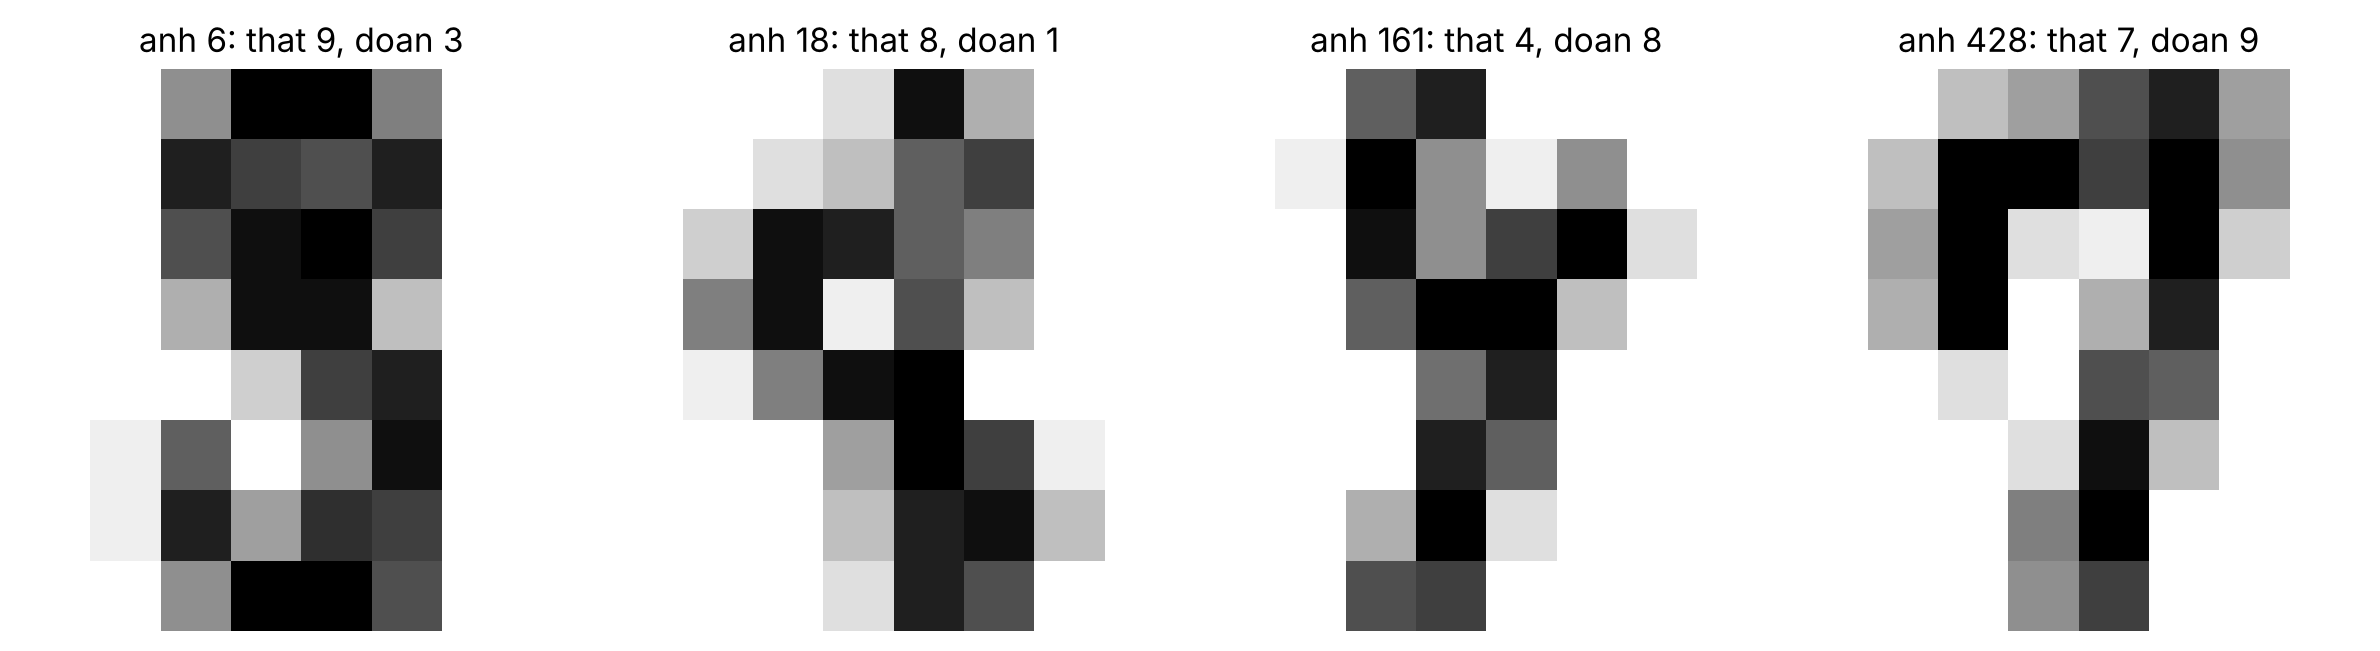

In [13]:
X_chu, y_chu = load_digits(return_X_y=True)
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(
    X_chu, y_chu, test_size=0.25, random_state=17, stratify=y_chu
)
svm_chu = SVC(kernel="rbf").fit(Xc_tr, yc_tr)
du_doan_chu = svm_chu.predict(Xc_te)
print(f"Accuracy: {accuracy_score(yc_te, du_doan_chu):.4f}")
print()

bang_nham_lan = confusion_matrix(yc_te, du_doan_chu)
print("Bang nham lan (hang la chu so that, cot la chu so doan)")
print(pd.DataFrame(bang_nham_lan,
                   index=[f"that {i}" for i in range(10)],
                   columns=[f"doan {i}" for i in range(10)]).to_string())
print()

# Liet ke cac cap bi nham: o nam ngoai duong cheo co gia tri lon hon 0
for that, doan in zip(*np.nonzero(bang_nham_lan - np.diag(np.diag(bang_nham_lan)))):
    print(f"That la {that}, doan la {doan}: {bang_nham_lan[that, doan]} anh")

# Ve va luu tung anh bi doan sai
anh_sai = np.flatnonzero(du_doan_chu != yc_te)
fig, truc = plt.subplots(1, len(anh_sai), figsize=(3 * len(anh_sai), 3.4))
for ax, i in zip(np.atleast_1d(truc), anh_sai):
    ax.imshow(Xc_te[i].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"anh {i}: that {yc_te[i]}, doan {du_doan_chu[i]}")
    ax.axis("off")
    plt.imsave(f"anh_sai_{i}.png", Xc_te[i].reshape(8, 8), cmap="gray_r")
plt.tight_layout()
plt.show()

**Nhận xét:** Bảng nhầm lẫn gần như chỉ có số trên đường chéo: 446 trên 450 ảnh được đoán đúng (0.9911). Có bốn ô ngoài đường chéo, mỗi ô 1 ảnh: 4 bị đoán thành 8, 7 thành 9, 8 thành 1 và 9 thành 3. Các chữ số 0, 1, 2, 3, 5, 6 không bị đoán sai ảnh nào. Không có cặp nào bị nhầm lặp lại, nên với 4 lỗi này chưa thể nói cặp nào là "hay nhầm", chỉ có thể nói các lỗi rơi vào những chữ có nét gần giống nhau.

## Bài tập 6: SVM trên dữ liệu lớn

In [14]:
from sklearn.exceptions import ConvergenceWarning

SO_LAN_DO = 3          # do 3 lan, lay lan nhanh nhat de bot nhieu cua may
cac_co = [2000, 5000, 10000, 20000]
thoi_gian = {"SVC": [], "LinearSVC": []}
canh_bao_hoi_tu = 0

print("     n   SVC (giay)   LinearSVC (giay)   SVC: vong lap   SVC: vecto ho tro")
for n in cac_co:
    X_lon, y_lon = make_classification(n_samples=n, n_features=20, random_state=0)

    lan_do_svc, lan_do_linear = [], []
    for _ in range(SO_LAN_DO):
        t0 = time.perf_counter()
        svc_lon = SVC().fit(X_lon, y_lon)
        lan_do_svc.append(time.perf_counter() - t0)

        with warnings.catch_warnings(record=True) as ds_canh_bao:
            warnings.simplefilter("always")
            t0 = time.perf_counter()
            LinearSVC().fit(X_lon, y_lon)
            lan_do_linear.append(time.perf_counter() - t0)
        canh_bao_hoi_tu += sum(issubclass(c.category, ConvergenceWarning)
                               for c in ds_canh_bao)

    thoi_gian["SVC"].append(min(lan_do_svc))
    thoi_gian["LinearSVC"].append(min(lan_do_linear))
    ty_le_ht = len(svc_lon.support_) / n
    print(f" {n:6d}   {thoi_gian['SVC'][-1]:9.4f}   {thoi_gian['LinearSVC'][-1]:14.4f}   "
          f"{int(svc_lon.n_iter_[0]):12d}   {len(svc_lon.support_):8d} ({ty_le_ht:.0%})")
print()

print("Thoi gian tang bao nhieu lan giua hai co lien tiep")
for ten, ds in thoi_gian.items():
    print(f" {ten:10s}", "   ".join(
        f"{cac_co[i]}->{cac_co[i + 1]}: x{ds[i + 1] / ds[i]:.2f}" for i in range(3)))
print()

# Neu thoi gian ~ n^p thi khi n gap doi, thoi gian tang 2^p lan
for ten, ds in thoi_gian.items():
    so_mu = np.polyfit(np.log(cac_co), np.log(ds), 1)[0]
    print(f"{ten:10s}: thoi gian ~ n^{so_mu:.2f}, "
          f"gap doi du lieu thi thoi gian tang khoang x{2 ** so_mu:.2f}")
print("So canh bao chua hoi tu cua LinearSVC:", canh_bao_hoi_tu)

     n   SVC (giay)   LinearSVC (giay)   SVC: vong lap   SVC: vecto ho tro
   2000      0.0311           0.0024           1178        456 (23%)


   5000      0.1378           0.0049           1846        913 (18%)


  10000      1.7897           0.0114           8932       4555 (46%)


  20000      5.6724           0.0226          10926       7448 (37%)

Thoi gian tang bao nhieu lan giua hai co lien tiep
 SVC        2000->5000: x4.43   5000->10000: x12.99   10000->20000: x3.17
 LinearSVC  2000->5000: x2.05   5000->10000: x2.31   10000->20000: x1.99

SVC       : thoi gian ~ n^2.38, gap doi du lieu thi thoi gian tang khoang x5.19
LinearSVC : thoi gian ~ n^0.99, gap doi du lieu thi thoi gian tang khoang x1.99
So canh bao chua hoi tu cua LinearSVC: 0


**Nhận xét:** `LinearSVC` học rất nhanh và tăng gần như tuyến tính: 0.0024, 0.0049, 0.0114, 0.0226 giây, mỗi lần dữ liệu gấp đôi thì thời gian tăng khoảng 2 lần (số mũ ước lượng 0.99). `SVC` chậm hơn nhiều và tăng nhanh hơn hẳn: 0.0311, 0.1378, 1.7897, 5.6724 giây, số mũ ước lượng 2.38, tức là dữ liệu gấp đôi thì thời gian tăng khoảng 5 lần. Ở 20000 mẫu, `SVC` chậm hơn `LinearSVC` khoảng 250 lần. `LinearSVC` không báo cảnh báo chưa hội tụ lần nào.